## linear-algebra

In [6]:
import numpy as np
my_list = [2, 6, 4, 9, 1]
my_vector = np.array(my_list)

print(type(my_list))
print(type(my_vector))
print(my_vector)

<class 'list'>
<class 'numpy.ndarray'>
[2 6 4 9 1]


In [8]:
#Addition
A = np.array([1, 2, 3])
B = np.array([4, 5, 6])
result = A + B
print(result)

[5 7 9]


In [10]:
#multiplication 

a = np.array([1, 7, 3])
scalar = 3
result = scalar * a
print(result)

[ 3 21  9]


In [11]:
# Dot Products

import numpy as np
vector_a = np.array([1, 2, 3])
vector_b = np.array([4, 5, 6])
dot_product = np.dot(vector_a, vector_b)
print(dot_product)

32


In [13]:
#Matrices 

matrix = [[1, 2, 3],
          [4, 5, 6],
          [7, 8, 9]]

print(type(matrix))
print(matrix[0][0])  
print(matrix[1][2])

<class 'list'>
1
6


In [15]:

#Matrix Addition   Matrix Subtraction 


matrix1 = np.array([[1, 2],
                    [3, 4]])
 
matrix2 = np.array([[5, 6],
                    [7, 8]])
 
result_addition = matrix1 + matrix2

print(type(matrix1))

print("Matrix Addition Result:")
print(result_addition)
 
result_subtraction = matrix1 - matrix2
print("Matrix Subtraction Result:")
print(result_subtraction)

<class 'numpy.ndarray'>
Matrix Addition Result:
[[ 6  8]
 [10 12]]
Matrix Subtraction Result:
[[-4 -4]
 [-4 -4]]


In [17]:
# Matrix Multiplication 

import numpy as np
 
matrix1 = np.array([[1, 2],
                    [3, 4]])
 
matrix2 = np.array([[5, 6],
                    [7, 8]])
 
result_multiplication = np.dot(matrix1, matrix2)

print(type(matrix1))

print("Matrix Multiplication Result:")
print(result_multiplication)

<class 'numpy.ndarray'>
Matrix Multiplication Result:
[[19 22]
 [43 50]]


# Linear Equations 

# Calculating Gaussian Kernel Matrix 

 machine learning and pattern re­cognition, a square matrix called the Gaussian ke­rnel matrix, also known as a radial basis function (RBF) kernel matrix, holds gre­at significance. Its purpose is to repre­sent the degre­e of similarity or distance betwe­en pairs of data points within a dataset. This valuable tool finds wide­ application in kernel methods like­ support vector machines (SVMs) and Gaussian processe­s.

 Gaussian ke­rnel matrix is obtained from the Gaussian (or normal) distribution. It e­valuates the similarity betwe­en two data points based on their Euclide­an distance. The matrix assigns higher similarity value­s to points in close proximity and lower values to those­ that are further apart.

In [28]:
# Linear Equations
# 
# Gaussian Elimination Method  

import numpy as np
 
def gaussian_elimination(A, b):
    # Determine the number of equations/variables (size of the system)
    n = len(A)

    print("number of equations/variables :",n,"\n" )
    
    # Create the augmented matrix [A | b] by combining coefficients and constants
    augmented_matrix = np.hstack((A, b))


    print("augmented_matrix :" ,augmented_matrix,"\n" )
 
    # --- PHASE 1: FORWARD ELIMINATION ---
    # Transform the matrix into an upper triangular form
    for i in range(n):
        
        # If the diagonal element (pivot) is zero, we need to swap rows
        if augmented_matrix[i, i] == 0:
            for k in range(i + 1, n):
                # Look for a row below that has a non-zero element in this column
                if augmented_matrix[k, i] != 0:
                    # Swap the current row 'i' with the row 'k'
                    augmented_matrix[[i, k]] = augmented_matrix[[k, i]]
                    break
            else:
                # If no non-zero pivot is found, the system has no unique solution
                return None
 
        # Normalize the current row so that the pivot element becomes 1
        pivot = augmented_matrix[i, i]
        augmented_matrix[i] /= pivot
 
        # Eliminate the entries below the current pivot to make them 0
        for j in range(i + 1, n):
            factor = augmented_matrix[j, i]
            # Subtract a multiple of row 'i' from row 'j'
            augmented_matrix[j] -= factor * augmented_matrix[i]
 
    # --- PHASE 2: BACK SUBSTITUTION ---
    # Initialize a column vector to store the calculated variables
    x = np.zeros((n, 1))
    
    # Solve from the bottom row up to the top row
    for i in range(n - 1, -1, -1):
        # Start with the constant value from the augmented column
        x[i] = augmented_matrix[i, -1]
        
        # Subtract the known components already solved in rows below
        for j in range(i + 1, n):
            x[i] -= augmented_matrix[i, j] * x[j]
 
    return x
 
# Coefficients matrix (A)
A = np.array([[2, 1, -1],
              [3, 2, 1],
              [1, -1, 2]], dtype=float)
 
# Constants vector (b)
b = np.array([[8],
              [11],
              [3]], dtype=float)
 
# Execute the algorithm
solution = gaussian_elimination(A, b)

# Output results
if solution is not None:
    print("Solution:")
    print(solution)
else:
    print("The system is not solvable.")


number of equations/variables : 3 

augmented_matrix : [[ 2.  1. -1.  8.]
 [ 3.  2.  1. 11.]
 [ 1. -1.  2.  3.]] 

Solution:
[[ 3.8]
 [ 0. ]
 [-0.4]]


The Gaussian kernel matrix (also known as the RBF (Radial Basis Function) kernel) measures the similarity between pairs of data points.  

using NumPy without using explicit for loops (which are slow for large datasets). This approach uses the mathematical expansion of the squared Euclidean distance:

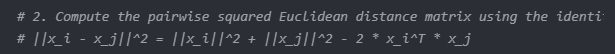

In [35]:
import numpy as np

def gaussian_kernel_matrix(X, sigma):
    """
    Computes the Gaussian (RBF) kernel matrix for a dataset X.
    
    Parameters:
    X: numpy array of shape (n_samples, n_features)
    sigma: bandwidth parameter (standard deviation)
    
    Returns:
    K: numpy array of shape (n_samples, n_samples)
    """
    # 1. Compute the squared norm of each row: shape (n_samples, 1)
    sq_norms = np.sum(X**2, axis=1, keepdims=True)
    
    # 2. Compute pairwise squared Euclidean distances using broadcasting
    # ||x_i - x_j||^2 = ||x_i||^2 + ||x_j||^2 - 2 * <x_i, x_j>
    pairwise_dists = sq_norms + sq_norms.T - 2 * np.dot(X, X.T)
    
    # 3. Apply the Gaussian kernel formula
    K = np.exp(-pairwise_dists / (2 * sigma**2))
    
    return K

# Example Usage:
# 3 data points in a 2-dimensional space
X = np.array([[1, 2],
              [5, 6]])
sigma = 1.0

K = gaussian_kernel_matrix(X, sigma)
print("Gaussian Kernel Matrix K:\n", K)


Gaussian Kernel Matrix K:
 [[1.00000000e+00 1.12535175e-07]
 [1.12535175e-07 1.00000000e+00]]


# Eigenvalues and Eigenvectors

In [32]:
import numpy as np

# Define the matrix A
A = np.array([[2, -1],
              [4, 3]])

# Compute eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(A)

# 1. Extract the first eigenvalue (index 0)
lam = eigenvalues[0]

# 2. Extract the corresponding eigenvector (column 0)
v = eigenvectors[:, 0]

# 3. Compute the left side of the equation: A multiplied by v
# Using np.dot() or the @ operator for matrix-vector multiplication
left_side = A @ v

# 4. Compute the right side of the equation: lambda multiplied by v
right_side = lam * v

# Print the results to visually verify they match
print(f"Eigenvalue (lambda): {lam}")
print(f"Eigenvector (v): {v}\n")

print(f"Left Side (A * v):  {left_side}")
print(f"Right Side (λ * v): {right_side}")

# 5. Check if they are numerically equal (accounting for tiny floating-point errors)
are_equal = np.allclose(left_side, right_side)
print(f"\nDo both sides match? {are_equal}")


Eigenvalue (lambda): (2.5+1.9364916731037083j)
Eigenvector (v): [ 0.1118034 -0.4330127j -0.89442719+0.j       ]

Left Side (A * v):  [ 1.11803399-0.8660254j  -2.23606798-1.73205081j]
Right Side (λ * v): [ 1.11803399-0.8660254j  -2.23606798-1.73205081j]

Do both sides match? True


Part 2: Mathematical Breakdown

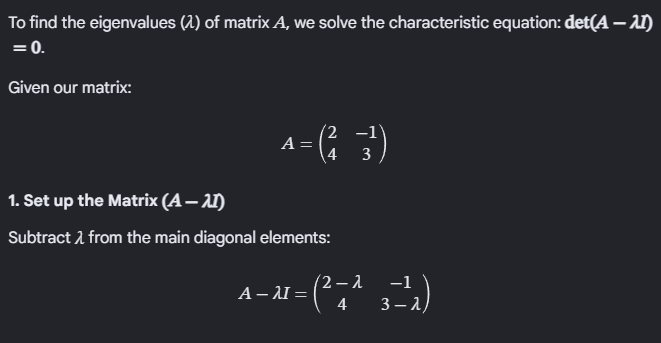

2. Calculate the Determinant

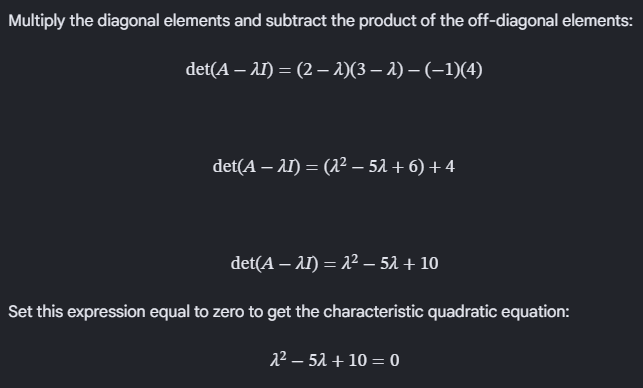

3. Solve Using the Quadratic Formula
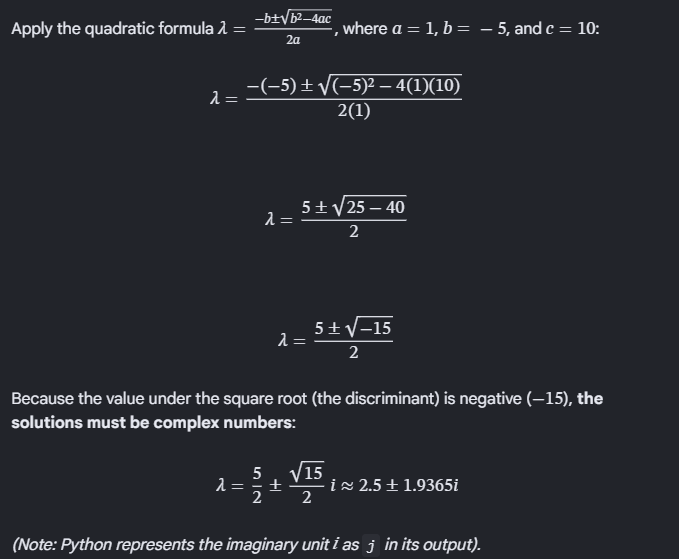


In [29]:
#Eigenvalues and Eigenvectors
import numpy as np
 
def eigenvalue_eigenvector(matrix):
    # np.linalg.eig calculates both eigenvalues and right eigenvectors of a square array
    # eigenvalues: a 1D array containing the scalar values (λ)
    # eigenvectors: a 2D array where each column corresponds to an eigenvalue
    eigenvalues, eigenvectors = np.linalg.eig(matrix)
    return eigenvalues, eigenvectors
 
# Define a 2x2 square matrix A
A = np.array([[2, -1],
              [4, 3]])
 
# Call the function to compute the values
eigenvalues, eigenvectors = eigenvalue_eigenvector(A)
 
# Print the results
print("Eigenvalues:")
print(eigenvalues)  # These may be complex numbers (containing 'j' for the imaginary unit)
 
print("\nEigenvectors:")
# NOTE: The eigenvectors are stored as COLUMNS, not rows.
# For example, eigenvectors[:, 0] is the column vector matching eigenvalues[0].
print(eigenvectors)


Eigenvalues:
[2.5+1.93649167j 2.5-1.93649167j]

Eigenvectors:
[[ 0.1118034 -0.4330127j  0.1118034 +0.4330127j]
 [-0.89442719+0.j        -0.89442719-0.j       ]]


# Linear Regression

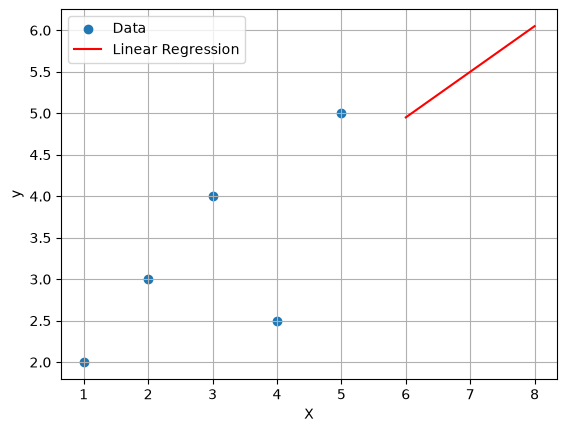

Slope (Coefficient): 0.5499999999999999
Intercept: 1.65


In [31]:
#Linear Regression

import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
 
# Independent variable data. .reshape(-1, 1) converts a 1D array into a 2D column matrix,
# which is required by scikit-learn's fit() method (expects shape: [n_samples, n_features]).
X = np.array([1, 2, 3, 4, 5]).reshape(-1, 1)  

# Dependent target variable data (1D array)
y = np.array([2, 3, 4, 2.5, 5])             
 
# Initialize the Linear Regression model object
model = LinearRegression()

# Train (fit) the model using ordinary least squares to find the line of best fit
model.fit(X, y)
 
# Retrieve the slope (m). model.coef_ returns an array of coefficients for each feature.
slope = model.coef_[0]

# Retrieve the y-intercept (c) where the regression line crosses the y-axis
intercept = model.intercept_

# New independent values to make predictions on. Must also be shaped as a 2D column matrix.
new_data = np.array([6, 7, 8]).reshape(-1, 1)

# Generate predictions for the new data points using the trained regression line
predictions = model.predict(new_data)
 
# Plot the original training data points as a scatter plot
plt.scatter(X, y, label='Data')

# Plot the predicted line of best fit across the new data points
plt.plot(new_data, predictions, color='red', label='Linear Regression')

# Label the horizontal and vertical axes
plt.xlabel('X')
plt.ylabel('y')

# Display the legend matching labels to their plot elements
plt.legend()

# Turn on the background grid lines for better readability
plt.grid(True)

# Render and display the visualization window
plt.show()
 
# Print the calculated slope of the best-fit line
print(f"Slope (Coefficient): {slope}")

# Print the calculated y-intercept of the model using an f-string
print(f"Intercept: {intercept}")
